# build a basic chatbot using langgraph

In [2]:
# 1. Annotated ek type hint hai, jisse hum kisi variable ya parameter ka expected type bata sakte hain.
#    LangGraph me iska use state ke messages ko specify karne me ho sakta hai.
from typing import Annotated

# 2. TypedDict dictionary ka structure define karta hai.
#    Matlab dictionary me kaun-kaun si keys hongi aur unki value ka type kya hoga.
from typing_extensions import TypedDict

# 3. StateGraph: LangGraph ka graph banata hai, jisme nodes aur edges hote hain.
#    START: Graph ki starting point ko represent karta hai.
#    END: Graph ke ending point ko represent karta hai.
from langgraph.graph import StateGraph, START, END

# 4. add_messages: Messages ko state me add/merge karne ka function hai.
#    Ye purane messages ko preserve karta hai aur naye messages ko add karta hai.
#    Message ID same hone par existing message update bhi ho sakta hai.
from langgraph.graph.message import add_messages

In [3]:
# State chatbot ki current information/data ko store karne ka structure define karta hai.
# TypedDict batata hai ki dictionary mein kaun-si keys aur unke types honge.
class State(TypedDict):

    # messages ek key hai, jisme messages ki list store hogi.
    # Annotated extra information attach karta hai ki list ko kaise update karna hai.
    # list batata hai ki messages ek list ke form mein honge.
    # add_messages naye messages ko purane messages ke saath add/merge karta hai,
    # taaki har baar purane messages overwrite na hon.
    messages: Annotated[list, add_messages]


# StateGraph ek naya graph/workflow builder banata hai.
# StateGraph(State) ka matlab hai ki graph is State structure ko follow karega.
# graph_builder variable mein ye graph builder object store hota hai.
graph_builder = StateGraph(State)


# graph_builder ko likhne par us object ka representation dikhta hai.
# Iska matlab graph builder create ho gaya hai; chatbot abhi complete nahi hua hai.
graph_builder

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
#initialize groq models 
# WAY 1: ChatGroq ka use karke model initialize karna
from langchain_groq import ChatGroq

# ChatGroq class Groq API ke through LLM model se connect karti hai.
# model parameter mein Groq ka model ID dete hain.
# llm variable mein initialized model object store hota hai.
llm = ChatGroq(model="openai/gpt-oss-120b")


# llm likhne par model object ka representation dikhega.
# Iska matlab object create ho gaya hai; actual response abhi generate nahi hua.
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.1', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000154089D01A0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000154089D0EC0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
from langchain.chat_models import init_chat_model

# Groq provider ke through LLM initialize karna
llm = init_chat_model(
    model="openai/gpt-oss-120b",
    model_provider="groq"
)

model bn gya ab nodes bna k chatbot bnayege

In [7]:
# Chatbot node: user ke message ko LLM tak bhejkar response generate karta hai.
#node definition(functionality)
def chatbot(state: State):

    # state["messages"] se conversation ke messages milte hain.
    # llm.invoke() messages ko process karke LLM ka response deta hai.
    # Response ko "messages" key ke through LangGraph ko return karte hain.
    return {"messages": [llm.invoke(state["messages"])]}

In [8]:
#ab hmlg node bnayege fr edge bnayege
graph_builder=StateGraph(State)
#adding node
graph_builder.add_node("llmchatbot",chatbot)#hmlg llmchatbot nam k node bnaye ar isme functionality dale h chatbot k upr s
# adding edge
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)
#compile the graph
graph=graph_builder.compile()

In [9]:
## Visualization graph
from IPython.display import Image, display

try:
    # Get the graph structure and convert it into a Mermaid PNG image.
    # Display the graph visually in the notebook.
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # Ignore errors during visualization.
    pass

In [10]:
graph.invoke({"messages":"Hi"
              })

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='42aa92f0-9717-41ec-a0d2-24777a394ccd'),
  AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi". We need to respond appropriately. As ChatGPT, greet back and ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 72, 'total_tokens': 120, 'completion_time': 0.100044487, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.017370463, 'prompt_tokens_details': None, 'queue_time': 0.403861637, 'total_time': 0.11741495}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_803c0ba83d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18cb7-90f7-731b-9c15-66c221cda170-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 48, 'total_tokens': 120, '

In [11]:
# add message s message add hora h, annotated s human message dikh rha hi, jbki hmlg thodi btaye the
response=graph.invoke({"messages":"Hi"
              })
response["messages"][-1].content

'Hello! How can I assist you today?'

In [12]:
# Stream the chatbot response
for event in graph.stream({"messages": "Hi How are you?"}):

    # Iterate through the values returned by the stream
    for value in event.values():

        # Print the latest AI message content
        print(value["messages"][-1].content)

Hello! I'm doing great, thanks for asking. How can I assist you today?


Is diagram mein explain kiya gaya hai ki LLM chatbot ko external tools ke saath kaise connect karte hain, taaki chatbot sirf apne trained knowledge par depend na rahe, balki external information bhi fetch kar sake.

Example: User asks – "Provide me the recent AI news."
1. Normal Chatbot vs Tool-based Chatbot
Normal Chatbot:
- User input deta hai.
- LLM prompt ko process karta hai.
- Apne trained knowledge ke basis par response generate karta hai.
- External data access nahi kar sakta jab tak koi tool/API available na ho.
Tool-based Chatbot:
- LLM ke saath external tools bind kiye jaate hain.
- LLM decide karta hai ki tool call karna hai ya directly answer dena hai.
- Tool se result milne ke baad LLM final response generate karta hai.
2. Working Flow (Diagram Explanation)
Example input: Provide me the recent AI news
1. Input: User chatbot ko query deta hai.
2. Chatbot / LLM: LLM user ke prompt ko understand karta hai.
3. Decision: LLM decide karta hai ki available information sufficient hai ya external tool ki need hai.
4. Tool Call: Agar recent AI news chahiye, toh LLM Tavily search tool ko call kar sakta hai.
5. ToolNode: LangGraph ka ToolNode tool call ko execute karta hai.
6. Result: Tavily search internet se latest AI news fetch karta hai.
7. Final Response: Tool ka result LLM ko wapas milta hai aur LLM user ko understandable answer deta hai.
3. External Tools
External tools are functions or APIs that provide additional capabilities to an LLM.

Examples:
- Tavily: Search recent information from the internet.
- Add: Perform addition.
- Subtract: Perform subtraction.
- Wikipedia: Fetch information from Wikipedia.
LLM khud in tasks ko directly perform nahi karta. Woh appropriate tool select karke execute karwata hai.
4. Tool Binding
Tool Binding means connecting external tools with an LLM so that the LLM can decide when and which tool to use.
llm_with_tools = llm.bind_tools(tools)



- llm → Language model.
- tools → Available external tools.
- bind_tools() → Tools ko LLM ke saath connect karta hai.
Important: Binding karne se tools execute nahi hote. LLM ko sirf tools ki availability aur unke usage ki information milti hai.
5. Creating a Custom Tool
Diagram ke right side mein def add() custom tool ka example hai.
@tooldef add(a: int, b: int) -> int:    """Add two numbers."""    return a + b



Ismein:
- @tool → Function ko LangChain tool banata hai.
- add → Tool ka name.
- a, b → Input arguments.
- Docstring → Tool kya kaam karta hai, uski description.
- return → Tool ka output.
LLM docstring aur arguments ke basis par samajhta hai ki tool kab use karna hai. #here what we are going to do

strt(prompt)->model with tool(jisme kch docstring hota jo decide krta h ki usko tool call krn ah ya ni , tooll k docstring m mention hta kch ckh jisse woprompt ko  match krta h, ar uske pas option hota h agr usse recent msg ni chhaiy to direct llm reply krke without tool, it can end also), tools jaise tavily(gooogle search), additional funct ko bind krke 

install tavily by putting it into requirement.txt
and then import it here and use, iska api v aata h, restrt kiye taki load dotenv v ho jaye


In [13]:
from langchain_tavily import TavilySearch
tool=TavilySearch(max_result=2)
tool.invoke("what is langgraph")


{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://academy.langchain.com/courses/intro-to-langgraph',
   'title': 'Introduction to LangGraph - Python',
   'content': 'No. LangGraph is an orchestration framework for complex agentic systems and is more low-level and controllable than LangChain agents. On the other hand, LangChain provides a standard interface to interact with models and other components, useful for straight-forward chains and retrieval flows.\n How is LangGraph different from other agent frameworks? [...] Yes. LangGraph is an MIT-licensed open-source library and is free to use.\n What is LangSmith Deployment?  \n\n  LangSmith Deployment helps you ship your agent in one click, using scalable infrastructure built for long-running tasks.\n\n## Ready to start shipping reliable agents faster?\n\nOur platform provides tools for every step of the agent development lifecycle — built to unlock powerful AI in 

In [14]:
##tavily do internet search,it give ans from various sites like gfg coursera or anything
# Custom function
def multiply(a: int, b: int) -> int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a * b


# Combine all tools into a list
tools = [tool, multiply]

In [15]:
llm_with_tools=llm.bind_tools(tools)
llm_with_tools


_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.1', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015408982C10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015408983610>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

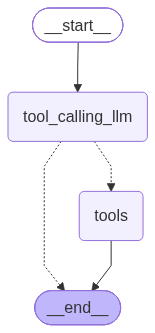

In [16]:
##stategraph(lareday imported upr)
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


## Node Definition
def tool_calling_llm(state: State):
    # LLM ko current messages state mein pass karte hain.
    # bind_tools wale LLM se response generate hota hai.
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


## Graph Creation
builder = StateGraph(State)

# add_node() mein pehle node ka name dete hain,
# comma ke baad us node ka function ya definition dete hain.
builder.add_node("tool_calling_llm", tool_calling_llm)

# Yahan "tools" node ka name hai aur ToolNode(tools) uski definition hai.
builder.add_node("tools", ToolNode(tools))
## Add Edges

# START se graph ka execution tool_calling_llm node se start hoga.
builder.add_edge(START, "tool_calling_llm")

# Conditional edges: LLM ke latest response ke basis par next node decide hota hai.
builder.add_conditional_edges(
    "tool_calling_llm",

    # Agar latest AI message mein tool call hai -> tools node par jayega.
    # Agar tool call nahi hai -> END par jayega.
    tools_condition
)

# Tools execute hone ke baad graph END ho jayega.
builder.add_edge("tools", END)


## Compile the Graph

# Builder ko compile karke executable graph banate hain.
graph = builder.compile()


## Visualize the Graph

# Graph ka Mermaid diagram generate karke image ke form mein display karte hain.
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
response=graph.invoke({"messages":"what is the recent ai news"})

In [18]:
# response dictionary ke andar messages key ki value access karte hain.
# [-1] ka use karke messages list ka last (latest AI) message lete hain.
# .content se us message ka actual text response extract karte hain.

response["messages"][-1].content

'{"query": "AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.newsguardtech.com/ai-monitor/october-2026", "title": "Quarterly AI False Claim Monitor — October 2026 - NewsGuard", "content": "NewsGuard. Restoring trust and accountability\\n\\n## Quarterly AI False Claim Monitor — October 2026\\n\\n### Quarterly audit of the 10 leading generative AI tools and their propensity to repeat false claims on controversial topics in the news\\n\\nPublished Oct. 29, 2026\\n\\nIn October, NewsGuard tested the 10 leading chatbots — OpenAI’s ChatGPT-6, xAI’s Grok, Inflection’s Pi, Anthropic’s Claude, Mistral’s Vibe, Microsoft’s Copilot, Meta AI, Google’s Gemini, Perplexity’s answer engine, and DeepSeek AI — on 10 provably false claims that NewsGuard analysts had identified spreading online about candidates and election processes ahead of the Nov. 3, 2026, vote.\\n\\nDownload the Report [...] Download the Report \\n\\nTo download this Ne

In [19]:
# Response ke messages list mein present har message ko iterate karte hain.
for m in response["messages"]:

    # pretty_print() har message ko readable format mein display karta hai.
    # Isse Human, AI aur Tool messages separately dekh sakte hain.
    m.pretty_print()

================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_cbf00308-0535-43cc-825e-21df036dca99)
 Call ID: fc_cbf00308-0535-43cc-825e-21df036dca99
  Args:
    query: AI news October 2026
    search_depth: advanced
    time_range: month
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.newsguardtech.com/ai-monitor/october-2026", "title": "Quarterly AI False Claim Monitor — October 2026 - NewsGuard", "content": "NewsGuard. Restoring trust and accountability\n\n## Quarterly AI False Claim Monitor — October 2026\n\n### Quarterly audit of the 10 leading generative AI tools and their propensity to repeat false claims on controversial topics 

In [20]:
#upr m mention h ki tavily seach toolcall h, avi wale m multiply k hoga
response=graph.invoke({"messages":"multiply of two and three "})

In [21]:
# Response ke messages list mein present har message ko iterate karte hain.
for m in response["messages"]:

    # pretty_print() har message ko readable format mein display karta hai.
    # Isse Human, AI aur Tool messages separately dekh sakte hain.
    m.pretty_print()

================================ Human Message =================================

multiply of two and three 
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_eb2b7a65-5174-4599-a7a7-e2b6ce9eb60b)
 Call ID: fc_eb2b7a65-5174-4599-a7a7-e2b6ce9eb60b
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [22]:
response=graph.invoke({"messages":"give me the recent ai news then multiply of two and three "})

In [23]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

give me the recent ai news then multiply of two and three 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_e0e469d6-4497-45ea-bde6-a2c2d9f52c08)
 Call ID: fc_e0e469d6-4497-45ea-bde6-a2c2d9f52c08
  Args:
    query: latest AI news
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=TVRCcMlvR10", "title": "AI News: 24 Things You Need To Know This Week", "content": "# AI News: 24 Things You Need To Know This Week\n## Channel: Matt Wolfe (verified)\n1.02M subscribers\n2.7K likes\n\n### Description\n153,232 views\nPosted: 2026-10-23\nSign into Hyperagent with your existing ChatGPT plan, or choose a paid plan and g

#ye recnt ai news k bd multiply kr ni rha, qki flow m toolk bd end h,
#  hm chhate ba ek esa chij bnana jisme ye resonse back jaye llm k pas tool s,
#  fr llm second uery le fr tol k pas aake multiply kre, fr response jaye llm kpas, the end ho jaye
#iske liye we will use reAct agent , isko hi react  agent architecture bolte h, 3 key term hota h
"""
react agent ky h
ReAct Agent = Reasoning + Acting Agent

ReAct ek AI agent approach hai jisme LLM pehle situation ko understand karta hai, phir action leta hai (tool call), aur tool ke result ko observe karke next decision leta hai.

Simple words mein: Think → Act → Observe → Think Again → Final Answer"""
1. ReAct Agent: Reason → Act → Observe
ReAct stands for Reasoning + Acting. It is a pattern in which an AI agent thinks about what action is required, performs that action using a tool, and observes the result.

There are 3 main steps:
1. Reason (Think)
- LLM understands the user's query.
- Decides what needs to be done.
- Selects the appropriate tool if required.
2. Act (Action)
- Agent performs the selected action.
- Calls an external tool or API.
- Example: Tavily Search, Calculator, Database, etc.
3. Observe (Observation)
- Agent receives the result from the tool.
- Checks whether the result is sufficient.
- If more information is required, it can reason and act again.


## React agent workflow

In [24]:
##stategraph(lareday imported upr)
## StateGraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


## Node Definition
def tool_calling_llm(state: State):
    # LLM ko current messages state mein pass karte hain.
    # bind_tools wale LLM se response generate hota hai.
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


## Graph Creation
builder = StateGraph(State)

# add_node() mein pehle node ka name dete hain,
# comma ke baad us node ka function ya definition dete hain.
builder.add_node("tool_calling_llm", tool_calling_llm)

# Yahan "tools" node ka name hai aur ToolNode(tools) uski definition hai.
builder.add_node("tools", ToolNode(tools))
## Add Edges

# START se graph ka execution tool_calling_llm node se start hoga.
builder.add_edge(START, "tool_calling_llm")

# Conditional edges: LLM ke latest response ke basis par next node decide hota hai.
builder.add_conditional_edges(
    "tool_calling_llm",

    # Agar latest AI message mein tool call hai -> tools node par jayega.
    # Agar tool call nahi hai -> END par jayega.
    tools_condition
)

# Tools execute hone ke baad graph tooling calling llm k pas  jayega.
builder.add_edge("tools", "tool_calling_llm")


## Compile the Graph

# Builder ko compile karke executable graph banate hain.
graph = builder.compile()


## Visualize the Graph

# Graph ka Mermaid diagram generate karke image ke form mein display karte hain.
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


ValueError: Failed to reach https://mermaid.ink API while trying to render your graph after 1 retries. To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)`

In [ ]:
response=graph.invoke({"messages":"give me the recent ai news then multiply of two and three "})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

give me the recent ai news then multiply of two and three 
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_27f30f07-6153-449d-b125-59c32c451a55)
 Call ID: fc_27f30f07-6153-449d-b125-59c32c451a55
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3fcc9bcf-7e58-4a70-9ff9-6d5a65a6aa56)
 Call ID: fc_3fcc9bcf-7e58-4a70-9ff9-6d5a65a6aa56
  Args:
    query: latest AI news October 2026
    search_depth: fast
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.bbc.co.uk/sc

In [ ]:
# ab dekho upr m dono output agya ki ai k recent news dene k bd wapas llm k pas gya ra llm fr wapas multiply fr llm k pas gy fr end

## adding memory to the llmmodle_with_tools

In [ ]:
response=graph.invoke({"messages":"my name is ritika jaiswal "})
for m in response["messages"]:
    m.pretty_print()#it wil not call the tool, it wil directly ans

================================ Human Message =================================

my name is ritika jaiswal 
================================== Ai Message ==================================

Nice to meet you, Ritika Jaiswal! If there's anything I can help you with, just let me know.


In [ ]:
response=graph.invoke({"messages":"what is my name? "})
for m in response["messages"]:
    m.pretty_print()#it wil not call the tool, it wil directly ans

================================ Human Message =================================

what is my name? 
================================== Ai Message ==================================

I don’t have any information about your name. If you’d like me to address you by a specific name, just let me know!


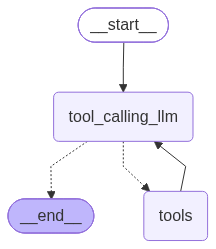

In [ ]:
##stategraph(lareday imported upr)
## StateGraph
#using same stategraph, just import checkpoint memory saver wala part
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()#ye v add kiye ar niche compile m pass kiye


## Node Definition
def tool_calling_llm(state: State):
    # LLM ko current messages state mein pass karte hain.
    # bind_tools wale LLM se response generate hota hai.
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


## Graph Creation
builder = StateGraph(State)

# add_node() mein pehle node ka name dete hain,
# comma ke baad us node ka function ya definition dete hain.
builder.add_node("tool_calling_llm", tool_calling_llm)

# Yahan "tools" node ka name hai aur ToolNode(tools) uski definition hai.
builder.add_node("tools", ToolNode(tools))
## Add Edges

# START se graph ka execution tool_calling_llm node se start hoga.
builder.add_edge(START, "tool_calling_llm")

# Conditional edges: LLM ke latest response ke basis par next node decide hota hai.
builder.add_conditional_edges(
    "tool_calling_llm",

    # Agar latest AI message mein tool call hai -> tools node par jayega.
    # Agar tool call nahi hai -> END par jayega.
    tools_condition
)

# Tools execute hone ke baad graph tooling calling llm k pas  jayega.
builder.add_edge("tools", "tool_calling_llm")


## Compile the Graph

# Builder ko compile karke executable graph banate hain.
graph = builder.compile(checkpointer=memory)


## Visualize the Graph

# Graph ka Mermaid diagram generate karke image ke form mein display karte hain.
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


to use this memory, ek thread id hona chahiye, config m

In [ ]:
# Thread ID define karte hain, jisse conversation ki memory maintain rahe.
config = {"configurable": {"thread_id": "1"}}

# User ka message graph ko config ke saath pass karte hain.
response = graph.invoke(
    {"messages": "Hi my name is Krish"},
    config=config
)

# Complete response display karte hain.
response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='f54d7025-c22e-4de2-a72b-630c238cc991'),
  AIMessage(content='Hi Krish! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Probably they want a greeting. We can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 348, 'total_tokens': 396, 'completion_time': 0.099178064, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.007471938, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.392821772, 'total_time': 0.106650002}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18ab5-962d-725c-86c0-3a1101ec4ce6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens'

In [ ]:
response["messages"][-1].content

'Hi Krish! Nice to meet you. How can I help you today?'

In [ ]:
response = graph.invoke(
    {"messages": "what is my name"},
    config=config
)

# Complete response display karte hain.
response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='f54d7025-c22e-4de2-a72b-630c238cc991'),
  AIMessage(content='Hi Krish! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Probably they want a greeting. We can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 348, 'total_tokens': 396, 'completion_time': 0.099178064, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.007471938, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.392821772, 'total_time': 0.106650002}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18ab5-962d-725c-86c0-3a1101ec4ce6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens'

In [ ]:
response = graph.invoke(
    {"messages": "hey, do u remember my name"},
    config=config
)

# Complete response display karte hain.
response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='f54d7025-c22e-4de2-a72b-630c238cc991'),
  AIMessage(content='Hi Krish! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Probably they want a greeting. We can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 348, 'total_tokens': 396, 'completion_time': 0.099178064, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.007471938, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.392821772, 'total_time': 0.106650002}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18ab5-962d-725c-86c0-3a1101ec4ce6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens'

##  Streaming

In [25]:
# MemorySaver: Conversation ki history ko memory mein save karta hai
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

# Superbot node: User ke message ka response generate karta hai
def superbot(state: State):
    return {"messages": [llm.invoke(state['messages'])]}
    # llm.invoke() → User ke messages ko LLM ko send karta hai
    # Response ko messages list mein return karta hai

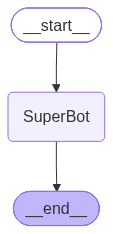

In [27]:
# StateGraph create karna using State structure
graph = StateGraph(State)

# Node add karna: SuperBot function execute hoga
graph.add_node("SuperBot", superbot)

# Edges: Execution ka flow define karna
graph.add_edge(START, "SuperBot")  # START se SuperBot node par jayega
graph.add_edge("SuperBot", END)    # SuperBot ke baad execution end hoga

# Graph compile karna aur memory attach karna
graph_builder = graph.compile(checkpointer=memory)

# Graph ka visual diagram display karna
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [28]:
# Invocation: Graph ko execute/run karna

# Thread ID: Conversation ko unique identity dena
config = {"configurable": {"thread_id": "1"}}

# Graph ko input message dena aur execute karna
graph_builder.invoke(
    {'messages': 'Hi, My name is Krish And I like cricket'},
    config=config
)

{'messages': [HumanMessage(content='Hi, My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='8b4630c5-0cee-4dd2-8541-efd67afbb9b8'),
  AIMessage(content='Hey Krish! 👋 Great to meet you.  \n\nI see you’re into cricket—awesome! Do you have a favorite team or player? Are you more into watching the matches, playing yourself, or maybe both? Let me know what you’re most excited about in the cricket world right now!', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user just says hi and introduces themselves. We should greet, ask about cricket preferences perhaps. Keep friendly.'}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 82, 'total_tokens': 183, 'completion_time': 0.21077869, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.003496801, 'prompt_tokens_details': None, 'queue_time': 0.353995155, 'total_time': 0.214275491}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerpri

# streaming
short  m do
Streaming
AI ke response ko ek saath dene ke bajay chunks/parts mein receive karna = Streaming.

Two methods
1. stream() – Synchronous streaming.

2. astream() – Asynchronous streaming.

Two modes
1. Updates

Sirf node ka latest update deta hai.

Partial state show karta hai.

2. Values

Har step ke baad complete updated state deta hai.

Full state show karta hai.

Example
# Updates: Only new changes
for event in graph.stream(input, stream_mode="updates"):
    print(event)

# Values: Complete state after every step
for event in graph.stream(input, stream_mode="values"):
    print(event)

Append kab hota hai?

add_messages reducer hone par new messages existing messages ke saath append hote hain.

Remember: Updates = Only changes | Values = Full state.


In [ ]:
  # Updates: Har node ke baad sirf updated/new state deta hai
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream(
    {'messages': "Hi, My name is Krish And I like cricket"},
    config,
    stream_mode="updates"
):
    print(chunk)#sirf ai msg display hota output m yaha,agr stream mode updates rha to

{'SuperBot': {'messages': [AIMessage(content='Hi Krish! Nice to meet you. 🎉  \nCricket’s such a fun sport—do you have a favorite team or player? Are you more into watching matches, playing yourself, or maybe both? Let me know, and we can chat about any recent games, tournaments, or anything cricket‑related you’re interested in!', additional_kwargs={'reasoning_content': 'We need to respond per policy. The user introduced themselves: "Hi, My name is Krish And I like cricket". We should respond friendly, maybe ask about cricket preferences, etc. No disallowed content. Just a normal conversation.'}, response_metadata={'token_usage': {'completion_tokens': 126, 'prompt_tokens': 82, 'total_tokens': 208, 'completion_time': 0.261163853, 'completion_tokens_details': {'reasoning_tokens': 49}, 'prompt_time': 0.003793786, 'prompt_tokens_details': None, 'queue_time': 0.352134525, 'total_time': 0.264957639}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_02b0d31eca', 'service_tier': '

In [ ]:
# Values: Har node ke baad complete updated state deta hai
for chunk in graph_builder.stream(
    {'messages': "Hi, My name is Krish And I like cricket"},
    config,
    stream_mode="values"
):
    print(chunk)#Output: agr stream mode values rha to
#- HumanMessage → User ka input.
#- AIMessage → AI ka response.

In [ ]:
# Create a new thread
config = {"configurable": {"thread_id": "4"}}

# Stream graph execution using updates mode
for chunk in graph_builder.stream(
    {'messages': "Hi, My name is Krish And I like cricket"},
    config,
    stream_mode="updates"
):
    print(chunk)

In [31]:
## value m phle wala chat continue hote hue ye continue hoga output  
for chunk in graph_builder.stream(
    {'messages': "I also like cricket"},
    config,
    stream_mode="values"
):
    print(chunk)

{'messages': [HumanMessage(content='I also like cricket', additional_kwargs={}, response_metadata={}, id='091c3adf-88a8-4108-ac8a-a75aad98bfc6')]}
{'messages': [HumanMessage(content='I also like cricket', additional_kwargs={}, response_metadata={}, id='091c3adf-88a8-4108-ac8a-a75aad98bfc6'), AIMessage(content='That’s great! Cricket has such a rich mix of strategy, skill, and excitement. Do you have a favorite format—Test, ODI, or T20? And are there any teams or players you follow closely? Whether you’re cheering for a particular nation in the World Cup, rooting for a franchise in the IPL, or just enjoying the classic five‑day battles, there’s always something fascinating to talk about. Let me know what you love most about the game!', additional_kwargs={'reasoning_content': 'We need to respond. The user says "I also like cricket". Likely they are continuing a conversation about sports preferences. We can respond positively, ask about their favorite team or player, discuss cricket. Keep 

In [ ]:
# Create a new conversation thread
config = {"configurable": {"thread_id": "5"}}

# Asynchronous streaming: Events ko asynchronously receive karna
#when u need mch more debugging nd all tb use kro isko, qki bht lmba deta hr kch
async for event in graph_builder.astream_events(
    {"messages": ["Hi My name is Krish and I like to play cricket"]},
    config,
    version="v2"
):
    print(event)  # Har event ko print karna

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a18ccd-4d96-76fa-a9e8-7063d42202d7', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='38170d86-5714-4c7a-b9d4-02d15c8773a2')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a18ccd-4d99-7272-8525-4cc1ef6f1929', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:3da348b3-4bba-3ac7-a1d9-c622471ff797'}, 'parent_ids': ['01a18ccd-4d96-76fa-a9e8-7063d42202d7']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':

# HUman in the loop 
Human Feedback in the Loop (HITL)
Meaning: AI execution ke beech human se approval ya feedback lena.

Why Human Assistance?
- AI ke decisions verify karne ke liye.
- Sensitive actions approve karne ke liye.
- Wrong actions prevent karne ke liye.
Working:
1. START → Chatbot
2. Chatbot → ToolNode / Human Assistance
3. Human gives feedback (Yes/No).
4. Yes → Continue execution.
5. No → Stop or modify execution.
Important terms:
- Tavily: Web search tool.
- Interrupt: AI execution temporarily pause karna.
- Resume: Human feedback ke baad execution continue karna

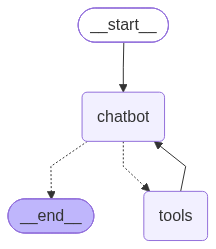

In [33]:
from typing import Annotated
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

# NEW: Command and interrupt import for human feedback
from langgraph.types import Command, interrupt


# Define State
class State(TypedDict):
    messages: Annotated[list, add_messages]


graph_builder = StateGraph(State)
# Human assistance ko tool banane ke liye @tool decorator
@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human."""

    # NEW: Interrupt execution and ask human for feedback
    human_response = interrupt({"query": query})

    # Return human's response
    return human_response["data"]
# Tavily search tool
tool = TavilySearch(max_results=2)

# Both tools: Tavily + Human Assistance
tools = [tool, human_assistance]

# Bind tools with LLM
llm_with_tools = llm.bind_tools(tools)


# Chatbot node
def chatbot(state: State):
    message = llm_with_tools.invoke(state["messages"])

    # Return AI message to state
    return {"messages": [message]}


# Add chatbot node
graph_builder.add_node("chatbot", chatbot)

# Create ToolNode
tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)
# Conditional edge: Decide whether to call a tool or END
graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition
)

# After tool execution, return to chatbot
graph_builder.add_edge("tools", "chatbot")

# Starting point
graph_builder.add_edge(START, "chatbot") 
# Save conversation history
memory = MemorySaver()

# Compile graph with checkpointer
graph = graph_builder.compile(checkpointer=memory)

from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # Visualization requires extra dependencies
    pass

In [34]:
# User input: Human assistance request
user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"

# Same thread ID to maintain conversation memory
config = {"configurable": {"thread_id": "1"}}

# Stream graph execution with complete state
events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_0c1c18e0-7557-4252-baa9-43420a3badac)
 Call ID: fc_0c1c18e0-7557-4252-baa9-43420a3badac
  Args:
    query: User requests expert guidance and assistance for building an AI agent.
================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_0c1c18e0-7557-4252-baa9-43420a3badac)
 Call ID: fc_0c1c18e0-7557-4252-baa9-43420a3badac
  Args:
    query: User requests expert guidance and assistance for building an AI agent.


Important concept:
- User query mein assistance word use hua hai.
- human_assistance tool ke docstring mein bhi assistance mentioned hai.
- LLM query ka meaning aur tool description samajhkar matching tool select karta hai.
- Isliye LLM human_assistance tool call karta hai.
- interrupt() execution pause karke human feedback leta hai.

In [35]:
# Human ka response (approval/feedback)
human_response = (
    "We, the experts are here to help! We'd recommend you "
    "check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

# Command import kiya tha: from langgraph.types import Command
# Command(resume=...) ka use karke paused graph ko resume karna
human_command = Command(resume={"data": human_response})

# Resume graph execution with the same thread config
events = graph.stream(
    human_command,
    config,
    stream_mode="values"
)

# Display updated messages
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (fc_0c1c18e0-7557-4252-baa9-43420a3badac)
 Call ID: fc_0c1c18e0-7557-4252-baa9-43420a3badac
  Args:
    query: User requests expert guidance and assistance for building an AI agent.
================================= Tool Message =================================
Name: human_assistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent. It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

Absolutely—happy to help you get started on building a robust AI agent! Below is a concise roadmap, along with some concrete resources and next‑step suggestions. Feel free to let me know which areas you’d like to dive deeper into.

---

## 1️⃣ Define the Agent’s Purpose & Scope
| Question | Why It Matters |
|----------|----------------|
| **What problem

interrupt() → Jab AI ko human se question, approval ya feedback lena hota hai, tab execution pause karta hai.

Command(resume=...) → Jab human apna reply/feedback de deta hai, tab paused execution ko resume karta hai.